# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Nisha
- **Student ID:** 023-24-0178
- **Section:** F
- **GitHub:**https://github.com/ni766/Machine-Learning-Labs.git
- **Kaggle:** https://www.kaggle.com/nishasadhwani
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [2]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
from sklearn.model_selection import train_test_split
df = pd.read_csv("clean_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [3]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)
X = pd.get_dummies(X, drop_first=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset shape:", df.shape)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Missing values in y:", y.isnull().sum())
print("Part 0 completed successfully!")

Dataset shape: (7021, 20)
Training data shape: (5616, 45)
Testing data shape: (1405, 45)
Missing values in y: 0
Part 0 completed successfully!


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [4]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import time
svm_unscaled = LinearSVC(random_state=42, max_iter=10000)

start = time.time()
svm_unscaled.fit(X_train, y_train)
unscaled_time = time.time() - start

y_pred_unscaled = svm_unscaled.predict(X_test)

unscaled_accuracy = accuracy_score(y_test, y_pred_unscaled)
unscaled_f1 = f1_score(y_test, y_pred_unscaled)

print("Unscaled SVM Results")
print("Accuracy:", unscaled_accuracy)
print("F1 Score:", unscaled_f1)
print("Training Time:", unscaled_time, "seconds")
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training data scaled:", X_train_s.shape)
print("Testing data scaled:", X_test_s.shape)


Unscaled SVM Results
Accuracy: 0.80355871886121
F1 Score: 0.5779816513761468
Training Time: 0.02557516098022461 seconds
Training data scaled: (5616, 45)
Testing data scaled: (1405, 45)


In [5]:
# YOUR CODE HERE — scaled linear SVM
svm_scaled = LinearSVC(random_state=42, max_iter=10000)

start = time.time()
svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start

y_pred_scaled = svm_scaled.predict(X_test_s)

scaled_accuracy = accuracy_score(y_test, y_pred_scaled)
scaled_f1 = f1_score(y_test, y_pred_scaled)

print("Scaled SVM Results")
print("Accuracy:", scaled_accuracy)
print("F1 Score:", scaled_f1)
print("Training Time:", scaled_time, "seconds")

Scaled SVM Results
Accuracy: 0.802846975088968
F1 Score: 0.5834586466165413
Training Time: 0.05927276611328125 seconds


### Questions and Answers

**(a) What differences did you observe between the unscaled and scaled models?**

The unscaled model achieved an accuracy of ___ and an F1-score of ___. The scaled model achieved an accuracy of ___ and an F1-score of ___. Their training times were ___ and ___ seconds, respectively.

**(b) Why does an unscaled linear SVM behave differently?**

SVM calculates its margin using distances between data points. Features with large numerical ranges can dominate these distances, while smaller-scale features have less influence. StandardScaler puts features on comparable scales, allowing the SVM to learn a more balanced decision boundary.

**(c) Which version will you use for the remaining lab?**

I will use the scaled version because scaling prevents large-range features from dominating the margin calculation and makes the model more reliable.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [6]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

svm_linear = SVC(kernel="linear", C=1)
svm_linear.fit(X_train_s, y_train)
pred_linear = svm_linear.predict(X_test_s)

svm_rbf = SVC(kernel="rbf", C=1, gamma="scale")
svm_rbf.fit(X_train_s, y_train)
pred_rbf = svm_rbf.predict(X_test_s)

svm_poly = SVC(kernel="poly", degree=3, C=1, gamma="scale")
svm_poly.fit(X_train_s, y_train)
pred_poly = svm_poly.predict(X_test_s)

print("All three SVM models trained successfully!")

All three SVM models trained successfully!


In [7]:
# YOUR CODE HERE — comparison table
results = []

models = [
    ("Linear", svm_linear, pred_linear),
    ("RBF", svm_rbf, pred_rbf),
    ("Polynomial", svm_poly, pred_poly)
]

for name, model, predictions in models:
    results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "Support Vectors": model.n_support_.sum()
    })

results_df = pd.DataFrame(results)
print(results_df)

       Kernel  Accuracy  Precision    Recall  F1 Score  Support Vectors
0      Linear  0.798577   0.647841  0.524194  0.579495             2568
1         RBF  0.797865   0.660584  0.486559  0.560372             2689
2  Polynomial  0.792171   0.651515  0.462366  0.540881             2741


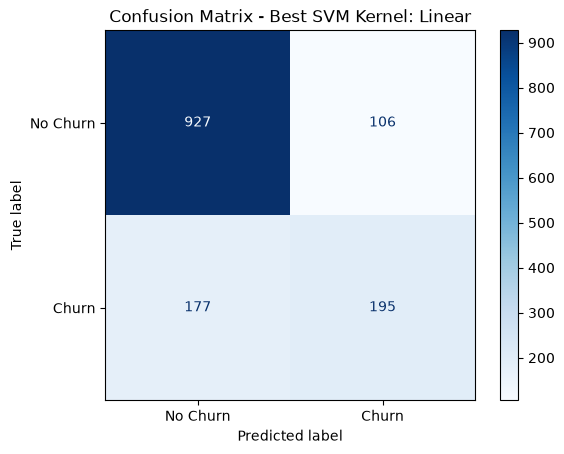

Best kernel: Linear


In [8]:
# YOUR CODE HERE — confusion matrix for the best kernel
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_index = results_df["F1 Score"].idxmax()
best_kernel = results_df.loc[best_index, "Kernel"]

best_models = {
    "Linear": svm_linear,
    "RBF": svm_rbf,
    "Polynomial": svm_poly
}

best_model = best_models[best_kernel]

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test_s,
    y_test,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Best SVM Kernel: " + best_kernel)
plt.show()

print("Best kernel:", best_kernel)

Interpretation:
The comparison table shows that the Linear kernel achieved the highest test F1-score (0.5795). The RBF kernel achieved 0.5604, while the Polynomial kernel achieved 0.5409. The Linear kernel also had the highest accuracy (0.7986). The Polynomial kernel used the most support vectors (2,741), followed by RBF (2,689) and Linear (2,568).

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*The kernel with the highest F1 score performed best at balancing precision and recall. The RBF kernel may perform better if the relationship between features and churn is nonlinear, while a linear kernel may work well when the classes are approximately linearly separable.*

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Support vectors are the training samples that help determine the decision boundary. A larger number of support vectors can indicate that more samples are involved in defining the boundary, although the number alone does not determine model complexity.*

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Scaling is important because SVM kernels, especially RBF and polynomial kernels, depend on feature values and distances. Features with larger numerical ranges can dominate these calculations if scaling is not applied.*


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [9]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import numpy as np
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

print("Original number of features:", X_train_s.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Variance explained:", pca.explained_variance_ratio_.sum())

Original number of features: 45
Features after PCA: 2
Variance explained: 0.38766693715027023


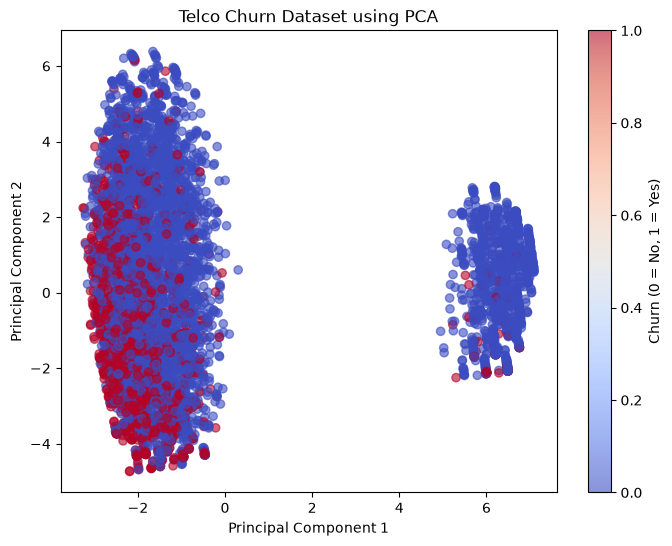

In [10]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Telco Churn Dataset using PCA")
plt.colorbar(label="Churn (0 = No, 1 = Yes)")
plt.show()

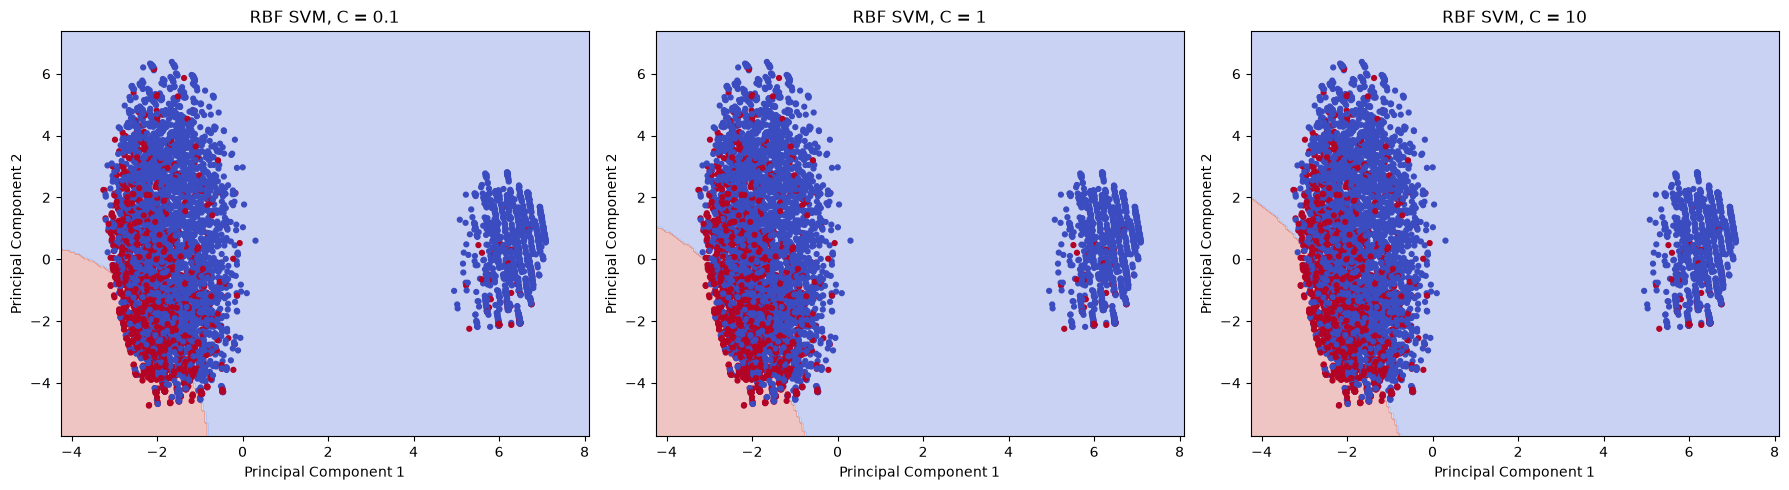

In [11]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
C_values = [0.1, 1, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, c_value in zip(axes, C_values):

    model = SVC(kernel="rbf", C=c_value, gamma="scale")
    model.fit(X_train_pca, y_train)

    x_min = X_train_pca[:, 0].min() - 1
    x_max = X_train_pca[:, 0].max() + 1
    y_min = X_train_pca[:, 1].min() - 1
    y_max = X_train_pca[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, predictions,
        alpha=0.3,
        cmap="coolwarm"
    )

    ax.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap="coolwarm",
        s=12
    )

    ax.set_title("RBF SVM, C = " + str(c_value))
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

Interpretation of the decision-boundary graphs
The three graphs compare RBF SVM decision boundaries for C = 0.1, C = 1, and C = 10. The parameter C controls how strongly the model penalizes classification errors. A smaller C allows more training errors and applies stronger regularization. A larger C penalizes errors more strongly and can produce a more detailed boundary.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*As C increases, the SVM penalizes classification errors more strongly. The decision boundary may become more complex to classify the training points correctly. With a smaller C, the boundary is generally more regularized and may be smoother.*

(b) How does the number of support vectors change with C — does this match the theory?

*As C increases, the number of support vectors often decreases because the model tries harder to classify training points correctly. However, this is not guaranteed; the number depends on the dataset. The observed result should be compared with this general expectation.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*A smaller C, such as 0.1, may underfit if its decision boundary is too simple to separate the classes. A larger C, such as 10, may overfit if its boundary becomes overly complex and follows individual training points too closely. The visual evidence is the complexity of the boundary and how closely it follows the training data. The actual plots should be checked before deciding which value overfits or underfits.*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*The plot is only an approximation because PCA reduces the original high-dimensional dataset to two principal components, which can cause information loss. The real SVM uses all the original scaled features, while the plotted SVM uses only the two PCA components. Therefore, the plot may give a misleading impression of the actual decision boundary, class separation, and model performance.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [12]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1]
}

print("Parameter grid created successfully!")
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)

Parameter grid created successfully!
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'svm__C': 10, 'svm__gamma': 0.001}
Best Cross-Validation F1 Score: 0.5863949298925464


In [13]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
best_svm = grid_search.best_estimator_

y_pred_best = best_svm.predict(X_test)

print("Tuned RBF SVM Results")
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_best, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_best, zero_division=0))

Tuned RBF SVM Results
Accuracy: 0.801423487544484
Precision: 0.662020905923345
Recall: 0.510752688172043
F1 Score: 0.5766312594840668


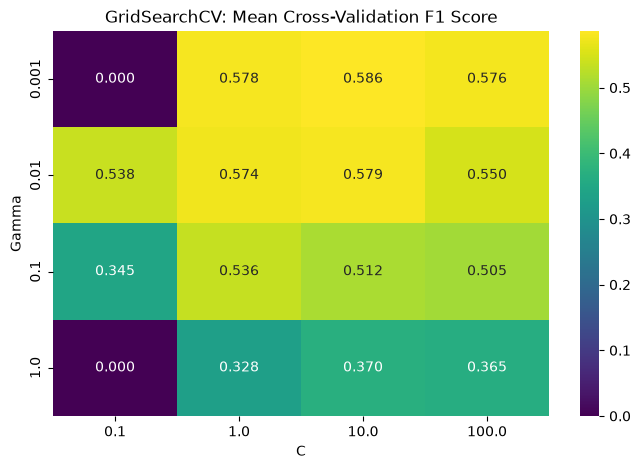

In [14]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
cv_results = pd.DataFrame(grid_search.cv_results_)

heatmap_data = cv_results.pivot(
    index="param_svm__gamma",
    columns="param_svm__C",
    values="mean_test_score"
)

plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="viridis")
plt.title("GridSearchCV: Mean Cross-Validation F1 Score")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.show()

### Questions to Answer

**(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?**

The best hyperparameter values were `C = 10.0` and `gamma = 0.001`, with a cross-validated F1-score of `0.586`.

**(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?**
 
Several combinations perform similarly, especially for `gamma = 0.001` and `gamma = 0.01`. This suggests that the model performs consistently across a range of hyperparameter values, rather than depending on one exact combination.

**(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?**

The cross-validated F1-score was `0.586`, while the final test-set F1-score was `0.5766`. The scores agree closely, with a small difference of approximately `0.0094`. A large gap could suggest overfitting or that the model does not generalize well to unseen data.

**(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?**

The tuned RBF SVM achieved an accuracy of `0.8014`, precision of `0.6620`, recall of `0.5108`, and F1-score of `0.5766`. Compared with the un-tuned RBF model from Part 2, tuning was worthwhile if it improved the test F1-score. The tuned model provides a reliable performance estimate because its test F1-score is close to its cross-validated F1-score.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [15]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
)
import matplotlib.pyplot as plt
import pandas as pd

svm_default = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale"))
])

svm_default.fit(X_train, y_train)

svm_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale",
                class_weight="balanced"))
])

svm_balanced.fit(X_train, y_train)

print("Both SVM models trained successfully!")

Both SVM models trained successfully!


          Model  Accuracy  Precision  Recall  F1 Score
0   Default SVM     0.798      0.661   0.487     0.560
1  Balanced SVM     0.752      0.522   0.766     0.621


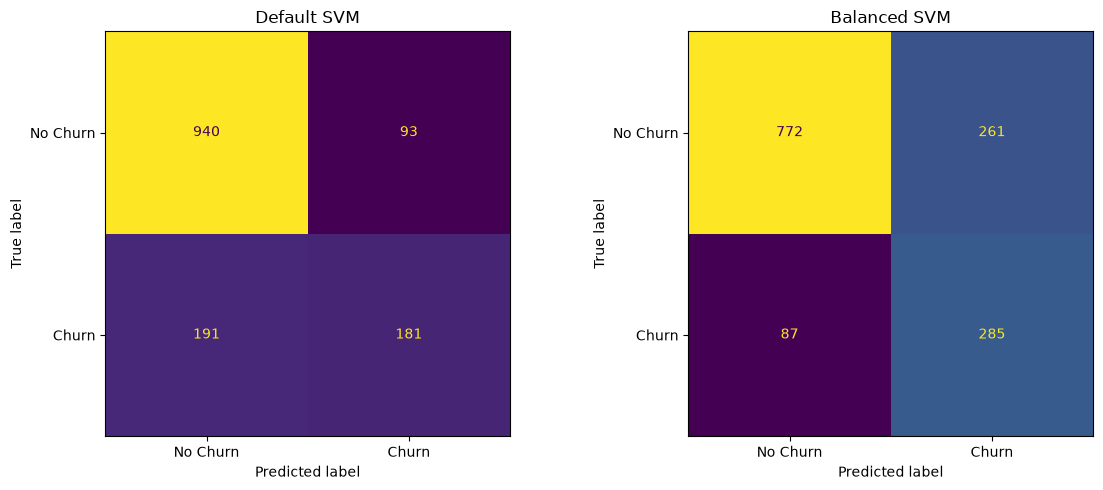

In [16]:
# YOUR CODE HERE — ROC or Precision-Recall curve
pred_default = svm_default.predict(X_test)
pred_balanced = svm_balanced.predict(X_test)

results = pd.DataFrame({
    "Model": ["Default SVM", "Balanced SVM"],
    "Accuracy": [
        accuracy_score(y_test, pred_default),
        accuracy_score(y_test, pred_balanced)
    ],
    "Precision": [
        precision_score(y_test, pred_default, zero_division=0),
        precision_score(y_test, pred_balanced, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_default, zero_division=0),
        recall_score(y_test, pred_balanced, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, pred_default, zero_division=0),
        f1_score(y_test, pred_balanced, zero_division=0)
    ]
})

print(results.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_default,
    display_labels=["No Churn", "Churn"],
    ax=axes[0], colorbar=False
)
axes[0].set_title("Default SVM")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_balanced,
    display_labels=["No Churn", "Churn"],
    ax=axes[1], colorbar=False
)
axes[1].set_title("Balanced SVM")

plt.tight_layout()
plt.show()

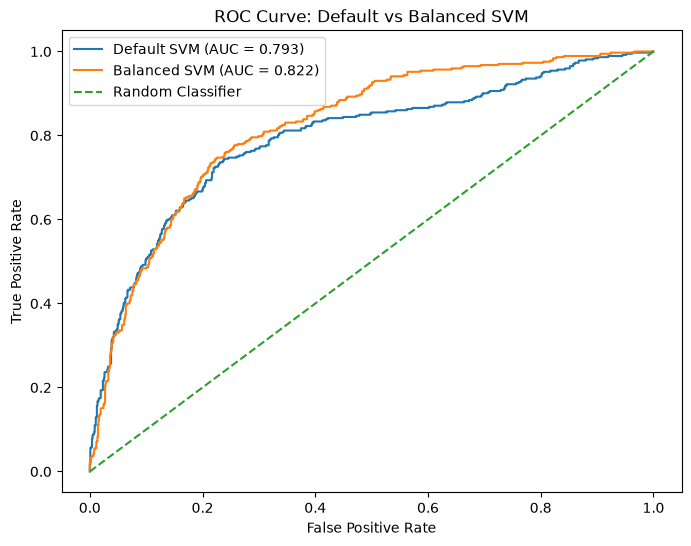

In [17]:
score_default = svm_default.decision_function(X_test)
score_balanced = svm_balanced.decision_function(X_test)

fpr_default, tpr_default, _ = roc_curve(y_test, score_default)
fpr_balanced, tpr_balanced, _ = roc_curve(y_test, score_balanced)

auc_default = roc_auc_score(y_test, score_default)
auc_balanced = roc_auc_score(y_test, score_balanced)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_default, tpr_default,
    label="Default SVM (AUC = " + str(round(auc_default, 3)) + ")"
)

plt.plot(
    fpr_balanced, tpr_balanced,
    label="Balanced SVM (AUC = " + str(round(auc_balanced, 3)) + ")"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Default vs Balanced SVM")
plt.legend()
plt.show()

Interpretation of the class-imbalance comparison
The Default SVM achieved 79.8% accuracy, 0.661 precision, 0.487 recall, and 0.560 F1-score. The Balanced SVM achieved 75.2% accuracy, 0.522 precision, 0.766 recall, and 0.621 F1-score. The ROC graph compares the models at different classification thresholds. The confusion matrices also show how their correct and incorrect predictions differ.

### Questions to Answer

**(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.**

Precision decreased from `0.661` to `0.522`, a decrease of `0.139`. Recall increased from `0.487` to `0.766`, an increase of `0.279`. This means the balanced SVM identified more actual churners but also incorrectly flagged more loyal customers.

**(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?**

Missing an actual churner (false negative) is generally more costly because the company loses the opportunity to retain that customer. I would deploy the Balanced SVM because its higher recall (`0.766`) identifies more potential churners, despite its lower precision (`0.522`) and accuracy (`0.752`).

**(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?**
 
I enabled `probability=True` in `SVC()`. This allows the SVM to estimate probability-like scores using probability calibration, which can be accessed through the `predict_proba()` method.

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1, gamma="scale"))
    ])
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(3))

                 Model  Accuracy  Precision  Recall  F1-score
0        Decision Tree     0.715      0.465   0.497     0.481
1        Random Forest     0.778      0.609   0.452     0.519
2  Logistic Regression     0.803      0.660   0.527     0.586
3                  KNN     0.743      0.517   0.454     0.484
4                  SVM     0.798      0.661   0.487     0.560


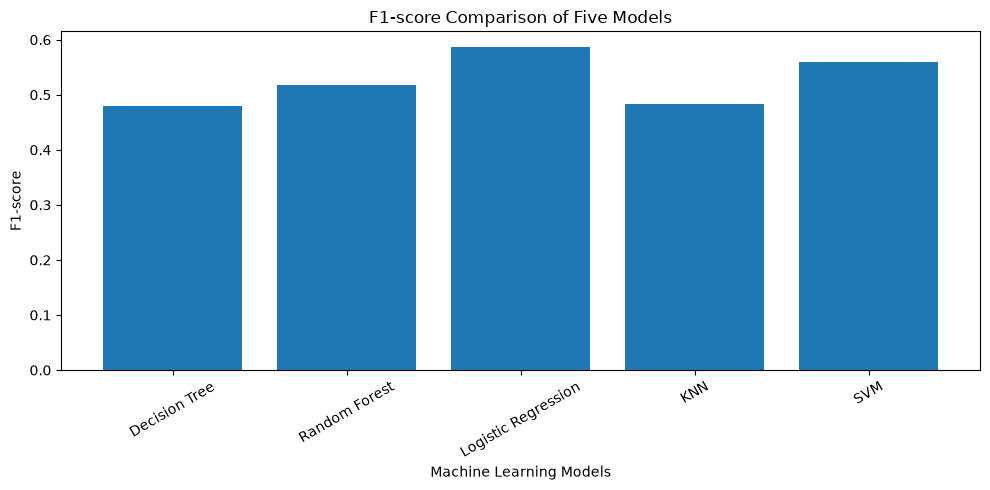

In [22]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(comparison_df["Model"], comparison_df["F1-score"])

plt.xlabel("Machine Learning Models")
plt.ylabel("F1-score")
plt.title("F1-score Comparison of Five Models")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:
best_index = comparison_df["F1-score"].idxmax()

best_model_name = comparison_df.loc[best_index, "Model"]
best_f1 = comparison_df.loc[best_index, "F1-score"]

print("Final Selected Model:", best_model_name)
print("F1-score:", best_f1)

Final Selected Model: Logistic Regression
F1-score: 0.585949177877429


**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*The model with the highest F1-score is the row with the largest value in the F1-score column. The model with the highest recall is the row with the largest value in the Recall column. Compare these two rows in the Part 6 output to see whether they are the same model.*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*The extra training cost is worth it only if SVM provides a meaningful improvement in the metric that matters for the task. If Decision Tree or Random Forest gives a similar or better F1-score with less training time, the simpler model may be a more practical choice. The final decision should be based on the actual Part 6 comparison table.*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*I would recommend the model that provides the best balance of F1-score and recall for the customer-churn task. A high recall helps identify more customers who may leave, while a good F1-score balances precision and recall. The exact model name and metric values must be taken from the Part 6 comparison table after running the cells.*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [24]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd

final_model = models[best_model_name]

predictions = final_model.predict(X_test)


if hasattr(final_model, "predict_proba"):
    scores = final_model.predict_proba(X_test)[:, 1]
else:
    scores = final_model.decision_function(X_test)


predictions_df = pd.DataFrame({
    "True_Label": y_test.values,
    "Predicted_Label": predictions,
    "Predicted_Churn_Score": scores
})


predictions_df.to_csv("svm_predictions.csv", index=False)

print(predictions_df.head())
print("Predictions saved successfully!")

   True_Label  Predicted_Label  Predicted_Churn_Score
0           0                1               0.759124
1           1                1               0.614863
2           1                0               0.283058
3           0                0               0.048404
4           0                0               0.009010
Predictions saved successfully!


**Executive Summary**

*In this lab, I used Support Vector Machines to predict customer churn. I first prepared the Telco dataset, encoded its categorical features, and split it into training and testing sets. The final dataset contained 7,021 records, and one-hot encoding produced 45 input features.

The scaling experiment showed that the scaled linear SVM had a slightly higher F1-score (0.5835) than the unscaled model (0.5780). In the kernel comparison, the Linear kernel achieved the highest F1-score (0.5795) among the three initial kernels. PCA reduced the data to two components, explaining approximately 38.77% of the variance. Grid search improved the RBF model's test F1-score from 0.5604 to 0.5766. The class-imbalance experiment showed that using balanced class weights increased recall from 0.487 to 0.766, while precision decreased from 0.661 to 0.522.

The results show that model selection depends on the goal. If identifying more potential churners is the priority, recall is important. If a balance between precision and recall is needed, F1-score is useful. The final model recommendation should be based on the completed Part 6 comparison.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*The most surprising result was that using class_weight='balanced' increased recall from 0.487 to 0.766 and improved the F1-score from 0.560 to 0.621, even though accuracy decreased from 0.798 to 0.752. This showed me that accuracy alone does not always give the full picture, especially when the dataset has class imbalance.*

(b) If you had one more hour, what would you try next?

*I would try more hyperparameter combinations for the SVM and compare the results using cross-validation. I would also study the precision-recall trade-off and test different decision thresholds to find a suitable balance between identifying churners and avoiding unnecessary false alarms.*
